# Credit Scorecard: Predicting Borrower Default

Building an application scorecard the way retail banks do: **Weight of Evidence (WoE) binning + logistic regression**, validated with **AUC, Gini and KS**, and converted into a points-based scorecard with an approval cut-off analysis.

**Data:** 150,000 borrowers from the "Give Me Some Credit" dataset (Kaggle). Target: did the borrower become 90+ days past due within 2 years?

**Steps**
1. Explore and clean the data
2. Split into train and test
3. Bin every variable and calculate WoE and Information Value (IV)
4. Select variables and fit a logistic regression on WoE values
5. Validate: AUC, Gini, KS and stability (PSI)
6. Convert the model into a points-based scorecard
7. Business use: score bands and approval cut-off

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. Explore and clean

In [2]:
df = pd.read_csv('data/cs-training.csv', index_col=0)

# Short, readable column names
df = df.rename(columns={
    'SeriousDlqin2yrs': 'default',
    'RevolvingUtilizationOfUnsecuredLines': 'revolving_util',
    'NumberOfTime30-59DaysPastDueNotWorse': 'late_30_59',
    'DebtRatio': 'debt_ratio',
    'MonthlyIncome': 'monthly_income',
    'NumberOfOpenCreditLinesAndLoans': 'open_credit_lines',
    'NumberOfTimes90DaysLate': 'late_90',
    'NumberRealEstateLoansOrLines': 'real_estate_loans',
    'NumberOfTime60-89DaysPastDueNotWorse': 'late_60_89',
    'NumberOfDependents': 'dependents',
})
print(df.shape)
print(f"Default rate: {df['default'].mean():.2%}")
df.describe().T

(150000, 11)
Default rate: 6.68%


,count,mean,std,min,25%,50%,75%,max
default,"150,000.0000",0.0668,0.2497,0.0000,0.0000,0.0000,0.0000,1.0000
revolving_util,"150,000.0000",6.0484,249.7554,0.0000,0.0299,0.1542,0.5590,"50,708.0000"
age,"150,000.0000",52.2952,14.7719,0.0000,41.0000,52.0000,63.0000,109.0000
late_30_59,"150,000.0000",0.4210,4.1928,0.0000,0.0000,0.0000,0.0000,98.0000
debt_ratio,"150,000.0000",353.0051,"2,037.8185",0.0000,0.1751,0.3665,0.8683,"329,664.0000"
monthly_income,"120,269.0000","6,670.2212","14,384.6742",0.0000,"3,400.0000","5,400.0000","8,249.0000","3,008,750.0000"
open_credit_lines,"150,000.0000",8.4528,5.1460,0.0000,5.0000,8.0000,11.0000,58.0000
late_90,"150,000.0000",0.2660,4.1693,0.0000,0.0000,0.0000,0.0000,98.0000
real_estate_loans,"150,000.0000",1.0182,1.1298,0.0000,0.0000,1.0000,2.0000,54.0000
late_60_89,"150,000.0000",0.2404,4.1552,0.0000,0.0000,0.0000,0.0000,98.0000


In [3]:
# Data quality issues
print('Missing values:')
print(df.isna().sum()[df.isna().sum() > 0])
print('\nBorrowers with age 0:', (df['age'] == 0).sum())
print('Late-payment counts coded 96 or 98:', (df['late_90'] >= 96).sum())
print('Revolving utilization above 100%:', (df['revolving_util'] > 1).sum())

Missing values:
monthly_income    29731
dependents         3924
dtype: int64

Borrowers with age 0: 1
Late-payment counts coded 96 or 98: 269
Revolving utilization above 100%: 3321


**Cleaning decisions**
- **Age 0** is impossible: 1 row removed.
- **96 and 98** in the late-payment counts are error codes, not real counts (nobody is late 98 times in 2 years). They're set to missing and get their own bin.
- **Missing income and dependents** are kept. In scorecards, "missing" is often predictive itself, so it gets its own bin instead of being filled in.
- **Extreme values** (utilization above 100%, huge debt ratios) are not removed: binning puts them in the top bin, so they can't distort the model.

In [4]:
df = df[df['age'] >= 18].copy()
for col in ['late_30_59', 'late_60_89', 'late_90']:
    df.loc[df[col] >= 96, col] = np.nan
print(df.shape)

(149999, 11)


## 2. Train / test split
70% to build the model, 30% held back to check it works on borrowers it has never seen. Stratified so both sets keep the same default rate.

In [5]:
train, test = train_test_split(df, test_size=0.3, random_state=42, stratify=df['default'])
print(f"Train: {len(train):,} rows, default rate {train['default'].mean():.2%}")
print(f"Test:  {len(test):,} rows, default rate {test['default'].mean():.2%}")

Train: 104,999 rows, default rate 6.68%
Test:  45,000 rows, default rate 6.68%


## 3. Binning, Weight of Evidence and Information Value

Each variable is cut into bins. For each bin:
- **WoE** = ln(% of goods in the bin / % of bads in the bin). Positive = safer than average, negative = riskier.
- **IV** = sum over bins of (% goods - % bads) x WoE. It measures how much a variable separates good and bad borrowers.

Rule of thumb for IV: under 0.02 useless, 0.02 to 0.1 weak, 0.1 to 0.3 medium, above 0.3 strong.

Bins are chosen by hand ("coarse classing") so they make business sense and the risk moves in a logical direction.

In [6]:
inf = np.inf
BINS = {
    'revolving_util':    [-inf, 0.1, 0.3, 0.5, 0.7, 0.9, inf],
    'age':               [-inf, 30, 40, 50, 60, 70, inf],
    'late_30_59':        [-inf, 0, 1, 2, inf],
    'late_60_89':        [-inf, 0, 1, inf],
    'late_90':           [-inf, 0, 1, inf],
    'debt_ratio':        [-inf, 0.2, 0.4, 0.6, 1, inf],
    'monthly_income':    [-inf, 2000, 4000, 6000, 8000, 10000, inf],
    'open_credit_lines': [-inf, 2, 5, 10, 15, inf],
    'real_estate_loans': [-inf, 0, 1, 2, inf],
    'dependents':        [-inf, 0, 1, 2, inf],
}

def assign_bin(series, bins):
    """Puts each value in its bin, missing values get their own 'Missing' bin."""
    binned = pd.cut(series, bins=bins).astype(str)
    return binned.where(series.notna(), 'Missing')

def woe_table(binned, target):
    """Counts, bad rate, WoE and IV per bin. +0.5 avoids dividing by zero on empty bins."""
    t = pd.DataFrame({'bin': binned, 'y': target}).groupby('bin').agg(n=('y', 'size'), bads=('y', 'sum'))
    t['goods'] = t['n'] - t['bads']
    t['pct_good'] = (t['goods'] + 0.5) / t['goods'].sum()
    t['pct_bad'] = (t['bads'] + 0.5) / t['bads'].sum()
    t['bad_rate'] = t['bads'] / t['n']
    t['woe'] = np.log(t['pct_good'] / t['pct_bad'])
    t['iv'] = (t['pct_good'] - t['pct_bad']) * t['woe']
    return t

# WoE is always calculated on TRAIN only, then applied to test
woe_tables = {col: woe_table(assign_bin(train[col], b), train['default']) for col, b in BINS.items()}
iv = pd.Series({col: t['iv'].sum() for col, t in woe_tables.items()}).sort_values(ascending=False)
iv.to_frame('information_value')

,information_value
revolving_util,1.0999
late_90,0.8867
late_30_59,0.7387
late_60_89,0.6002
age,0.2254
open_credit_lines,0.0790
monthly_income,0.0741
real_estate_loans,0.0560
debt_ratio,0.0418
dependents,0.0357


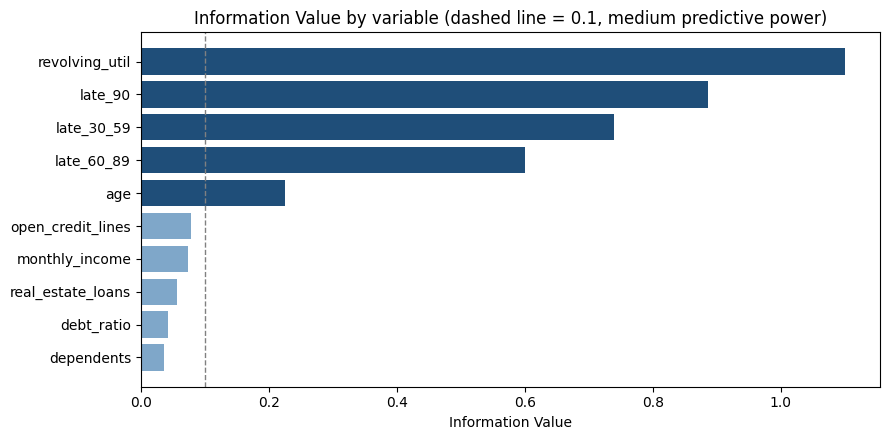

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#1f4e79' if v >= 0.1 else '#7fa7c9' if v >= 0.02 else '#cccccc' for v in iv]
ax.barh(iv.index[::-1], iv.values[::-1], color=colors[::-1])
ax.axvline(0.1, ls='--', color='grey', lw=1)
ax.set_title('Information Value by variable (dashed line = 0.1, medium predictive power)')
ax.set_xlabel('Information Value')
plt.tight_layout(); plt.savefig('images/information_value.png', dpi=150); plt.show()

In [8]:
# Example: revolving utilization and past lateness are the strongest signals
for col in ['revolving_util', 'late_90', 'age']:
    print(f'\n{col}')
    print(woe_tables[col][['n', 'bad_rate', 'woe']])


revolving_util
                 n  bad_rate     woe
bin                                 
(-inf, 0.1]  45152    0.0185  1.3348
(0.1, 0.3]   19731    0.0298  0.8476
(0.3, 0.5]   11187    0.0579  0.1519
(0.5, 0.7]    7919    0.0990 -0.4285
(0.7, 0.9]    7005    0.1489 -0.8934
(0.9, inf]   14005    0.2228 -1.3873

late_90
                 n  bad_rate     woe
bin                                 
(-inf, 0.0]  99093    0.0460  0.3957
(0.0, 1.0]    3738    0.3373 -1.9613
(1.0, inf]    1984    0.5544 -2.8548
Missing        184    0.5380 -2.7879

age
                  n  bad_rate     woe
bin                                  
(-inf, 30.0]   7530    0.1129 -0.5752
(30.0, 40.0]  17012    0.0980 -0.4175
(40.0, 50.0]  24597    0.0817 -0.2167
(50.0, 60.0]  24365    0.0621  0.0776
(60.0, 70.0]  19128    0.0358  0.6575
(70.0, inf]   12367    0.0237  1.0807


**Reading it:** borrowers using over 90% of their credit lines default about 10 times more often than those under 10%. One single 90-day late payment in the past pushes the default rate from under 5% to around a third. Older borrowers are safer.

## 4. Model: logistic regression on WoE values
Each raw value is replaced by the WoE of its bin, then a logistic regression is fitted. All variables have IV above 0.02, so all start in the model.

In [9]:
def to_woe(data):
    return pd.DataFrame({col: assign_bin(data[col], b).map(woe_tables[col]['woe']).fillna(0)
                         for col, b in BINS.items()})

X_train, X_test = to_woe(train), to_woe(test)
features = list(iv[iv >= 0.02].index)

model_1 = sm.Logit(train['default'], sm.add_constant(X_train[features])).fit(disp=0)
model_1.summary2().tables[1][['Coef.', 'P>|z|']]

,Coef.,P>|z|
const,-2.6027,0.0000
revolving_util,-0.6237,0.0000
late_90,-0.5277,0.0000
late_30_59,-0.5043,0.0000
late_60_89,-0.3828,0.0000
age,-0.3666,0.0000
open_credit_lines,0.0900,0.0846
monthly_income,-0.2394,0.0000
real_estate_loans,-0.5790,0.0000
debt_ratio,-0.8106,0.0000


**Sign check:** because WoE is positive for safe bins, every coefficient should be **negative** (higher WoE = lower default probability). `open_credit_lines` comes out **positive** and not significant (p around 0.08): it contradicts its own WoE pattern, which usually means its information is already captured by other variables. In a bank model a wrong-sign variable is not allowed, so it's removed.

In [10]:
features = [f for f in features if f != 'open_credit_lines']
model = sm.Logit(train['default'], sm.add_constant(X_train[features])).fit(disp=0)
model.summary2().tables[1][['Coef.', 'Std.Err.', 'P>|z|']]

,Coef.,Std.Err.,P>|z|
const,-2.6025,0.0150,0.0000
revolving_util,-0.6172,0.0146,0.0000
late_90,-0.5239,0.0135,0.0000
late_30_59,-0.5089,0.0156,0.0000
late_60_89,-0.3836,0.0168,0.0000
age,-0.3644,0.0336,0.0000
monthly_income,-0.2345,0.0531,0.0000
real_estate_loans,-0.5548,0.0631,0.0000
debt_ratio,-0.8249,0.0669,0.0000
dependents,-0.3850,0.0759,0.0000


## 5. Validation
- **AUC:** probability the model ranks a random bad borrower as riskier than a random good one
- **Gini** = 2 x AUC - 1, the standard in banking
- **KS:** the biggest gap between the cumulative % of bads and goods. Shows how well the score separates them.

The key check is that **test** results are close to **train**, meaning the model isn't overfitting.

In [11]:
p_train = model.predict(sm.add_constant(X_train[features]))
p_test = model.predict(sm.add_constant(X_test[features]))

def metrics(y, p):
    auc = roc_auc_score(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': max(tpr - fpr)}

results = pd.DataFrame({'train': metrics(train['default'], p_train),
                        'test': metrics(test['default'], p_test)})
results

,train,test
AUC,0.8555,0.8558
Gini,0.7110,0.7117
KS,0.5494,0.5546


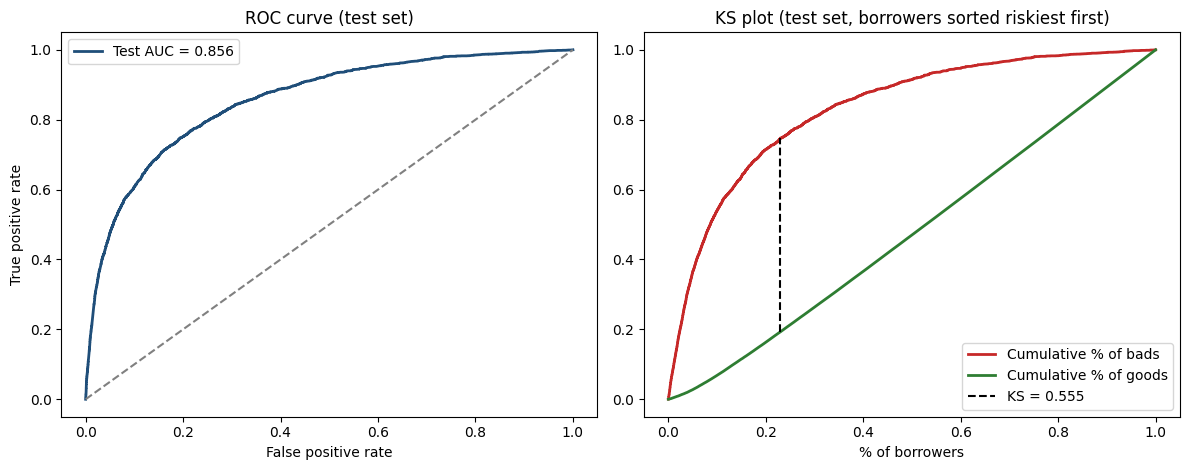

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
fpr, tpr, _ = roc_curve(test['default'], p_test)
axes[0].plot(fpr, tpr, color='#1f4e79', lw=2, label=f"Test AUC = {results.loc['AUC','test']:.3f}")
axes[0].plot([0, 1], [0, 1], ls='--', color='grey')
axes[0].set_title('ROC curve (test set)')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].legend()

order = np.argsort(-p_test.values)
y_sorted = test['default'].values[order]
cum_bad = np.cumsum(y_sorted) / y_sorted.sum()
cum_good = np.cumsum(1 - y_sorted) / (1 - y_sorted).sum()
x = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
ks_idx = np.argmax(cum_bad - cum_good)
axes[1].plot(x, cum_bad, color='#c62828', lw=2, label='Cumulative % of bads')
axes[1].plot(x, cum_good, color='#2e7d32', lw=2, label='Cumulative % of goods')
axes[1].vlines(x[ks_idx], cum_good[ks_idx], cum_bad[ks_idx], color='black', ls='--',
               label=f'KS = {cum_bad[ks_idx] - cum_good[ks_idx]:.3f}')
axes[1].set_title('KS plot (test set, borrowers sorted riskiest first)')
axes[1].set_xlabel('% of borrowers'); axes[1].legend()
plt.tight_layout(); plt.savefig('images/roc_ks.png', dpi=150); plt.show()

## 6. From model to scorecard points
Banks don't show probabilities to underwriters, they use **points**. Standard scaling:
- **600 points = odds of 50 goods to 1 bad**
- **every 20 points doubles the odds** ("Points to Double the Odds", PDO)

Each bin of each variable gets a number of points; a borrower's score is the sum.

In [13]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
intercept = model.params['const']
n = len(features)

rows = []
for col in features:
    beta = model.params[col]
    for bin_label, r in woe_tables[col].iterrows():
        points = -(beta * r['woe'] + intercept / n) * factor + offset / n
        rows.append({'variable': col, 'bin': bin_label, 'borrowers': int(r['n']),
                     'bad_rate': r['bad_rate'], 'woe': r['woe'], 'points': round(points)})
scorecard = pd.DataFrame(rows)
scorecard.to_csv('outputs/scorecard.csv', index=False)
scorecard[scorecard['variable'].isin(['revolving_util', 'late_90'])]

,variable,bin,borrowers,bad_rate,woe,points
0,revolving_util,"(-inf, 0.1]",45152,0.0185,1.3348,86
1,revolving_util,"(0.1, 0.3]",19731,0.0298,0.8476,78
2,revolving_util,"(0.3, 0.5]",11187,0.0579,0.1519,65
3,revolving_util,"(0.5, 0.7]",7919,0.0990,-0.4285,55
4,revolving_util,"(0.7, 0.9]",7005,0.1489,-0.8934,47
5,revolving_util,"(0.9, inf]",14005,0.2228,-1.3873,38
6,late_90,"(-inf, 0.0]",99093,0.0460,0.3957,68
7,late_90,"(0.0, 1.0]",3738,0.3373,-1.9613,33
8,late_90,"(1.0, inf]",1984,0.5544,-2.8548,19
9,late_90,Missing,184,0.5380,-2.7879,20


In [14]:
def score(data):
    total = pd.Series(0.0, index=data.index)
    for col in features:
        pts = scorecard[scorecard['variable'] == col].set_index('bin')['points']
        total += assign_bin(data[col], BINS[col]).map(pts).fillna(0)
    return total

train['score'] = score(train)
test['score'] = score(test)
print(f"Score range (test): {test['score'].min():.0f} to {test['score'].max():.0f}")
print(f"Test AUC using the rounded points: {roc_auc_score(test['default'], -test['score']):.4f}")

Score range (test): 412 to 627
Test AUC using the rounded points: 0.8558


In [15]:
# Example: scoring one applicant
applicant = pd.DataFrame([{'revolving_util': 0.85, 'age': 29, 'late_30_59': 1, 'late_60_89': 0, 'late_90': 0,
                           'debt_ratio': 0.45, 'monthly_income': 2500, 'real_estate_loans': 0, 'dependents': 1}])
print(f"Applicant score: {score(applicant).iloc[0]:.0f}")

Applicant score: 525


## 7. Business use: score bands and approval cut-off

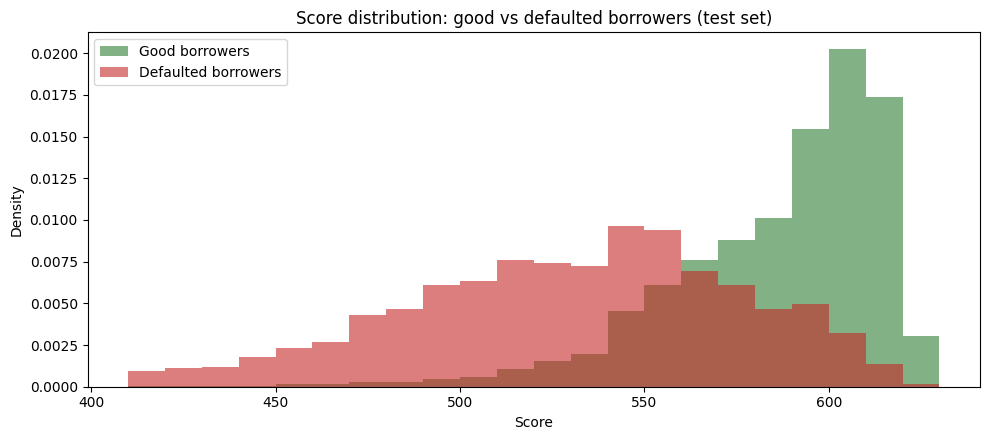

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins_hist = np.arange(test['score'].min() // 10 * 10, test['score'].max() + 10, 10)
ax.hist(test.loc[test['default'] == 0, 'score'], bins=bins_hist, alpha=0.6, density=True, color='#2e7d32', label='Good borrowers')
ax.hist(test.loc[test['default'] == 1, 'score'], bins=bins_hist, alpha=0.6, density=True, color='#c62828', label='Defaulted borrowers')
ax.set_title('Score distribution: good vs defaulted borrowers (test set)')
ax.set_xlabel('Score'); ax.set_ylabel('Density'); ax.legend()
plt.tight_layout(); plt.savefig('images/score_distribution.png', dpi=150); plt.show()

In [17]:
# Bad rate by score band (10 equal groups)
test['score_band'] = pd.qcut(test['score'], 10, duplicates='drop')
bands = test.groupby('score_band', observed=True).agg(borrowers=('default', 'size'), bad_rate=('default', 'mean'))
bands

,borrowers,bad_rate
score_band,,
"(411.999, 540.0]",4566,0.3581
"(540.0, 558.0]",4579,0.1138
"(558.0, 571.0]",4454,0.0622
"(571.0, 583.0]",4628,0.0436
"(583.0, 592.0]",4493,0.0280
"(592.0, 599.0]",5073,0.0207
"(599.0, 604.0]",4282,0.0128
"(604.0, 609.0]",4312,0.0095
"(609.0, 614.0]",4338,0.0058


In [18]:
# Cut-off table: if we only approve applicants at or above a score, what happens?
cutoffs = []
for c in range(int(test['score'].quantile(0.05)), int(test['score'].quantile(0.6)), 5):
    approved = test[test['score'] >= c]
    cutoffs.append({'cutoff': c,
                    'approval_rate': len(approved) / len(test),
                    'bad_rate_approved': approved['default'].mean(),
                    'bads_rejected_pct': 1 - approved['default'].sum() / test['default'].sum()})
cutoff_table = pd.DataFrame(cutoffs)
cutoff_table.to_csv('outputs/cutoff_table.csv', index=False)
cutoff_table

,cutoff,approval_rate,bad_rate_approved,bads_rejected_pct
0,516,0.9505,0.0449,0.3617
1,521,0.9428,0.0429,0.3953
2,526,0.9337,0.0407,0.4309
3,531,0.9225,0.0383,0.4717
4,536,0.9115,0.0360,0.5086
5,541,0.8985,0.0340,0.5436
6,546,0.8806,0.0316,0.5838
7,551,0.8472,0.0284,0.6403
8,556,0.8183,0.0254,0.6885
9,561,0.7827,0.0229,0.7320


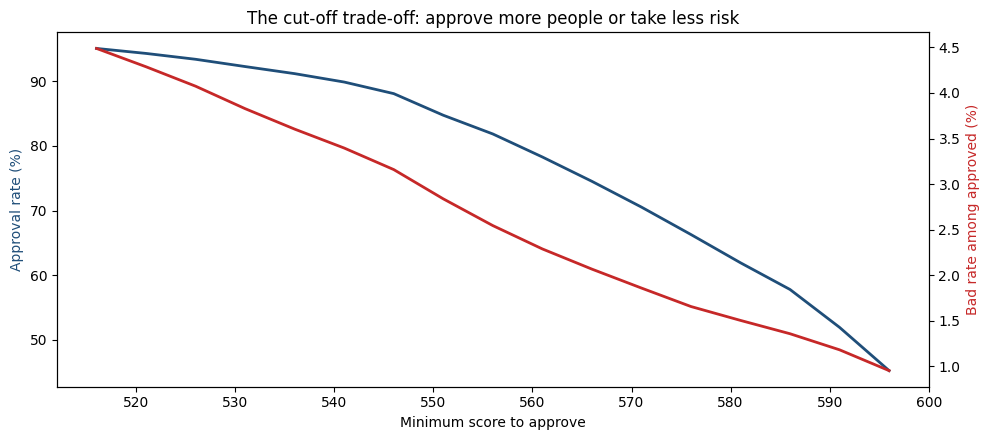

In [19]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(cutoff_table['cutoff'], cutoff_table['approval_rate'] * 100, color='#1f4e79', lw=2, label='Approval rate')
ax1.set_ylabel('Approval rate (%)', color='#1f4e79'); ax1.set_xlabel('Minimum score to approve')
ax2 = ax1.twinx()
ax2.plot(cutoff_table['cutoff'], cutoff_table['bad_rate_approved'] * 100, color='#c62828', lw=2, label='Bad rate of approved')
ax2.set_ylabel('Bad rate among approved (%)', color='#c62828')
ax1.set_title('The cut-off trade-off: approve more people or take less risk')
plt.tight_layout(); plt.savefig('images/cutoff_tradeoff.png', dpi=150); plt.show()

## 8. Stability check (PSI)
The **Population Stability Index** compares the score distribution of two populations. Banks run it every month to detect when the incoming applicants have drifted from the ones the model was built on. Under 0.1 = stable, 0.1 to 0.25 = monitor, above 0.25 = investigate.

In [20]:
edges = np.unique(np.quantile(train['score'], np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf
exp_pct = pd.cut(train['score'], edges).value_counts(normalize=True, sort=False)
act_pct = pd.cut(test['score'], edges).value_counts(normalize=True, sort=False)
psi = ((act_pct - exp_pct) * np.log(act_pct / exp_pct)).sum()
print(f'PSI train vs test: {psi:.4f}')

PSI train vs test: 0.0004


## Conclusions
- The scorecard ranks risk well: **Gini around 0.71 on unseen borrowers**, essentially the same as on training data, and the population is stable (PSI close to 0).
- **Credit utilization and past late payments dominate.** Behavior predicts default far better than demographics.
- `open_credit_lines` was dropped for a wrong-sign coefficient, a standard model governance rule.
- The cut-off table turns the model into a business decision: the bank chooses how much approval volume it's willing to trade for lower risk.

**Limitations:** no application date, so no out-of-time validation; bins are set by hand; the dataset is public and US-based. A production model would add out-of-time testing, reject inference and regular monitoring.